
# Metallicity Distribution Functions observadas

Notebook para descargar los siguientes catálogos de Vizier:
- **Haywood (2001)**: distribución de metalicidades de enanas del vecindario solar
- **Geneva–Copenhagen Survey III, Holmberg et al. (2009)**: estrellas F y G del vecindario solar
- **Adibekyan et al. (2012)**: 1111 estrellas FGK con abundancias detalladas, incluyendo $[\mathrm{Fe/H}]$ y $[\mathrm{Mg/H}]$

El objetivo es construir distribuciones de metalicidad observadas (MDF) y comparar las MDF obtenidas con distintas muestras estelares de su simulación 



## Metalicidad del modelo y abundancias observadas

El modelo de evolución química de caja cerrada sigue la metalicidad total del gas

$$
Z = \frac{M_{\rm metals}}{M_{\rm gas}}
$$

Para compararla con observaciones es útil escribirla en escala logarítmica respecto del Sol

$$
[\mathrm{M/H}]
=
\log_{10}\left(\frac{Z}{Z_\odot}\right)
$$

Los catálogos observacionales normalmente no miden directamente $Z$. En cambio, entregan abundancias de elementos individuales como $[\mathrm{Fe/H}]$ o $[\mathrm{Mg/H}]$

Por lo tanto, al comparar el modelo con los datos debemos decidir qué abundancia observacional utilizaremos como **trazador de la metalicidad global**.


In [24]:
!pip -q install astroquery

In [25]:
import numpy as np
import matplotlib.pyplot as plt


## Adibekyan et al. (2012)

El catálogo `J/A+A/545/A32/table4` contiene abundancias químicas para 1111 estrellas FGK.

Descargaremos directamente $[\mathrm{Fe/H}]$ y $[\mathrm{Mg/H}]$.


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# File path
dat_file = "adibekyan.dat"

# All column names
columns = [
    "Star", "Teff", "logg", "Fe_H", "Vtur",
    "Na_H", "e_Na_H", "o_Na_H", "Na_H_c",
    "Mg_H", "e_Mg_H", "o_Mg_H",
    "Al_H", "e_Al_H", "o_Al_H", "Al_H_c",
    "Si_H", "e_Si_H", "o_Si_H",
    "Ca_H", "e_Ca_H", "o_Ca_H",
    "ScI_H", "e_ScI_H", "o_ScI_H", "ScI_H_c",
    "ScII_H", "e_ScII_H", "o_ScII_H",
    "TiI_H", "e_TiI_H", "o_TiI_H", "TiI_H_c",
    "TiII_H", "e_TiII_H", "o_TiII_H",
    "V_H", "e_V_H", "o_V_H", "V_H_c",
    "CrI_H", "e_CrI_H", "o_CrI_H",
    "CrII_H", "e_CrII_H", "o_CrII_H", "CrII_H_c",
    "Mn_H", "e_Mn_H", "o_Mn_H",
    "Co_H", "e_Co_H", "o_Co_H", "Co_H_c",
    "Ni_H", "e_Ni_H", "o_Ni_H"
]

# Read data
adi = pd.read_csv(
    dat_file,
    sep=r"\s+",
    names=columns,
    comment="#"
)

# Select required columns
adi = adi[["Star", "Fe_H", "Mg_H"]].copy()

# Rename columns
adi.rename(columns={
    "Fe_H": "[Fe/H]",
    "Mg_H": "[Mg/H]"
}, inplace=True)

# Convert abundances to numeric
adi["[Fe/H]"] = pd.to_numeric(df["[Fe/H]"], errors="coerce")
adi["[Mg/H]"] = pd.to_numeric(df["[Mg/H]"], errors="coerce")

# Display catalog
print("Total stars:", len(df))
print(df.columns.tolist())
print(df.head())

# Extract valid metallicities
feh = adi["[Fe/H]"].dropna().to_numpy()
mgh = adi["[Mg/H]"].dropna().to_numpy()

print("Valid [Fe/H]:", len(feh))
print("Valid [Mg/H]:", len(mgh))

Total stars: 1111
['Star', '[Fe/H]', '[Mg/H]']
        Star  [Fe/H]  [Mg/H]
0  BD+062932   -0.84  -0.827
1  BD+063077   -0.36  -0.330
2  BD+083095   -0.77  -0.513
3  BD-002387    0.03  -0.147
4  BD-010184   -0.34  -0.323
Valid [Fe/H]: 1111
Valid [Mg/H]: 1111


/var/folders/36/rk32flss4bj4sbk5qc_2v8l00000gn/T/ipykernel_22654/480934200.py:40: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  adi.rename(columns={



#### Compare la distribución de $[\mathrm{Fe/H}]$ y $[\mathrm{Mg/H}]$ (visualizacion de histogramas)


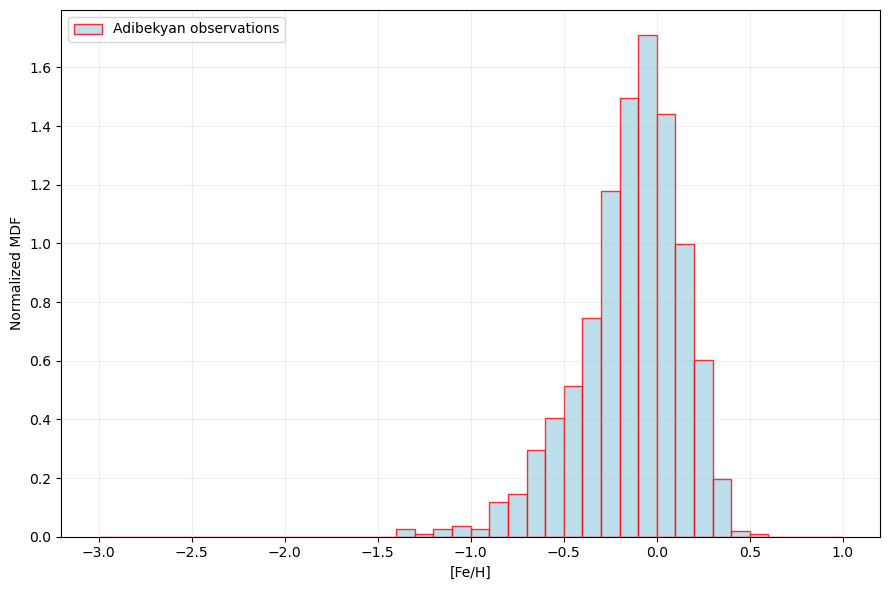

In [40]:
# Abundancias observacionales
feh_obs = pd.to_numeric(
    adi["[Fe/H]"], errors="coerce"
).to_numpy()

feh_obs = feh_obs[np.isfinite(feh_obs)]

# MDF
bins = np.arange(-3.0, 1.1, 0.1)

plt.figure(figsize=(9, 6))

plt.hist(
    feh_obs,
    bins=bins,
    density=True,
    color="lightblue",
    edgecolor="red",
    alpha=0.8,
    label="Adibekyan observations"
)

plt.xlabel("[Fe/H]")
plt.ylabel("Normalized MDF")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

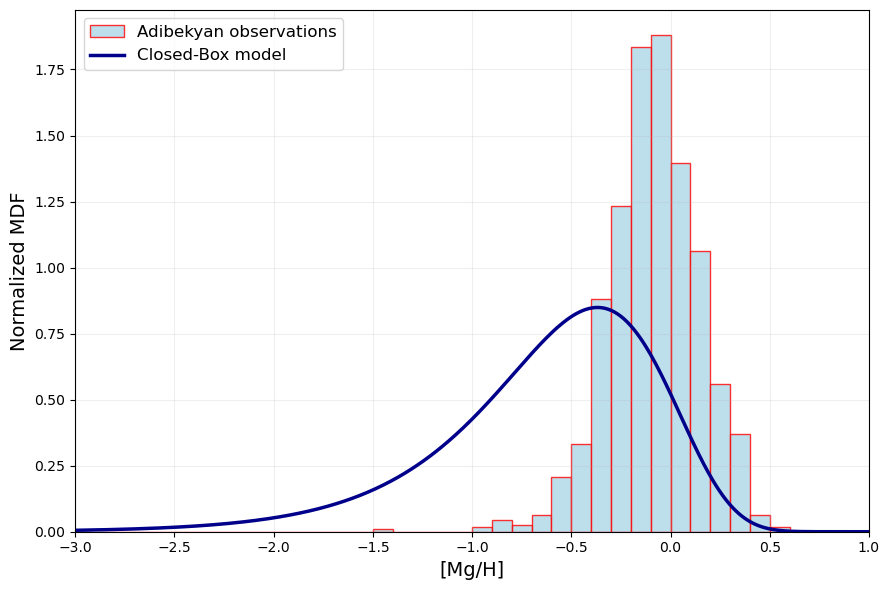

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Closed-box model parameters
# =========================

z_sun = 0.014
p = 0.006

mh_grid = np.linspace(-3, 1, 500)

# =========================
# Observational abundances [Mg/H]
# =========================

mgh_obs = pd.to_numeric(
    adi["[Mg/H]"], errors="coerce"
).to_numpy()

mgh_obs = mgh_obs[np.isfinite(mgh_obs)]

# =========================
# Closed-box model
# =========================

# Metallicity
Z = z_sun * 10**mh_grid

# Closed-box MDF
model = (np.log(10) / p) * Z * np.exp(-Z / p)

# Normalize
model /= np.trapezoid(model, mh_grid)

# =========================
# Plot MDF
# =========================

bins = np.arange(-3.0, 1.1, 0.1)

plt.figure(figsize=(9, 6))

plt.hist(
    mgh_obs,
    bins=bins,
    density=True,
    color="lightblue",
    edgecolor="red",
    alpha=0.8,
    label="Adibekyan observations"
)

plt.plot(
    mh_grid,
    model,
    color="darkblue",
    linewidth=2.5,
    label="Closed-Box model"
)

plt.xlabel("[Mg/H]", fontsize=14)
plt.ylabel("Normalized MDF", fontsize=14)
plt.xlim(-3, 1)
plt.legend(fontsize=12)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("ClosedBox_MgH.png", dpi=300)
plt.show()

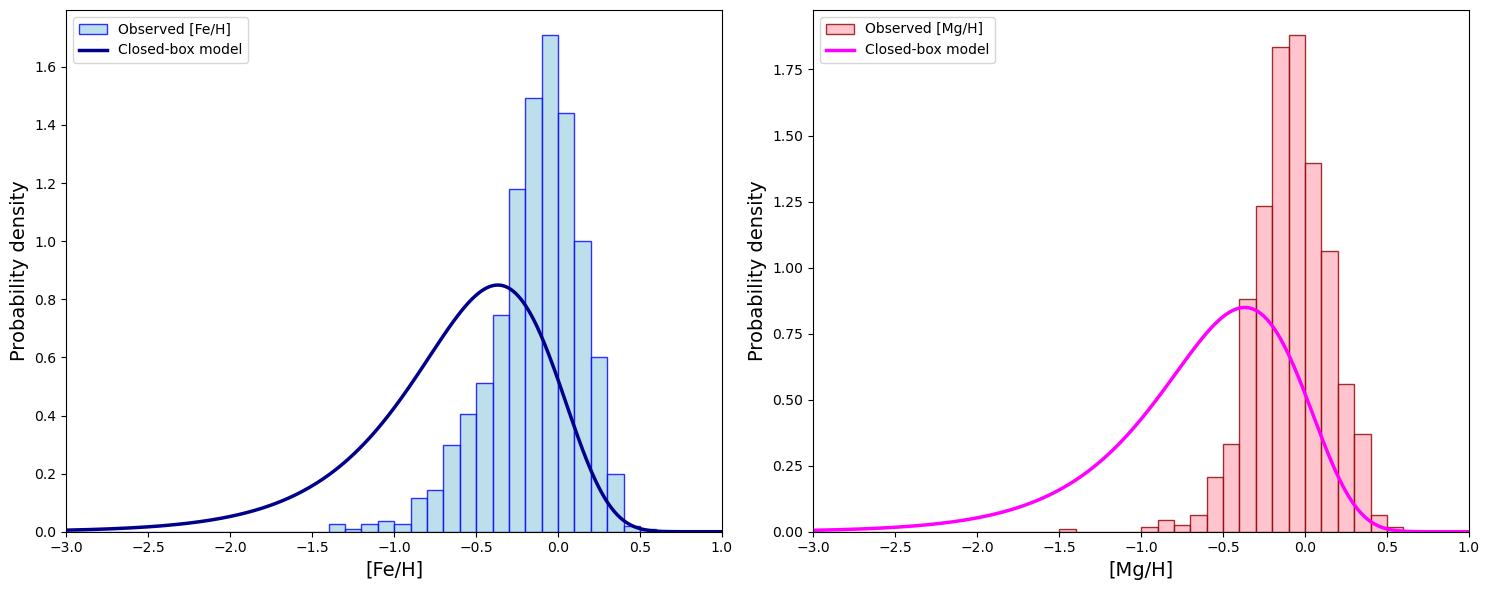

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot [Fe/H]
axes[0].hist(
    feh_obs,
    bins=np.arange(-3, 1.1, 0.1),
    density=True,
    color="lightblue",
    edgecolor="blue",
    alpha=0.8,
    label="Observed [Fe/H]"
)

axes[0].plot(
    mh_grid, model,
    color="darkblue",
    lw=2.5,
    label="Closed-box model"
)
axes[0].set_xlabel("[Fe/H]", fontsize=14)
axes[0].set_ylabel("Probability density", fontsize=14)
axes[0].set_xlim(-3, 1)
axes[0].legend()

# Plot [Mg/H]
axes[1].hist(
    mgh_obs,
    bins=np.arange(-3, 1.1, 0.1),
    density=True,
    color="lightpink",
    edgecolor="darkred",
    alpha=0.8,
    label="Observed [Mg/H]"
)

axes[1].plot(
    mh_grid, model,
    color="fuchsia",
    lw=2.5,
    label="Closed-box model"
)

axes[1].set_xlabel("[Mg/H]", fontsize=14)
axes[1].set_ylabel("Probability density", fontsize=14)
axes[1].set_xlim(-3, 1)
axes[1].legend()

# Final layout
plt.tight_layout()
plt.savefig("closeFeMg")
plt.show()

#ESTO EN EL INFORME
- ¿Tienen $[\mathrm{Fe/H}]$ y $[\mathrm{Mg/H}]$ exactamente la misma distribución?
- ¿Dónde aparecen las principales diferencias?
- ¿Qué podría hacer que Fe y Mg no sigan exactamente la misma evolución química?



## Haywood (2001)

El catálogo `J/MNRAS/325/1365/table3` contiene 348 estrellas.

La columna `ST` identifica con `*` las **selected long-lived dwarf stars**. Para construir la MDF utilizaremos solamente esa submuestra.


In [ ]:
seleccion = np.array(hay["ST"].filled(""), dtype=str) == "*"

hay_long = hay[seleccion]

feh_hay = np.array(hay_long["[Fe/H]"].filled(np.nan), dtype=float)
feh_hay = feh_hay[np.isfinite(feh_hay)]

print("Long-lived dwarfs:", len(hay_long))
print("Fe/H válidos:", len(feh_hay))



## Geneva–Copenhagen Survey III

El catálogo `V/130/gcs3` contiene 16682 estrellas F y G del vecindario solar.

Usaremos su estimación de $[\mathrm{Fe/H}]$.


In [79]:
!pip install -q datasets

In [81]:
%pip install --upgrade --no-cache-dir pyarrow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 140.1 kB/s  0:02:56 eta 0:00:020:00:08
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pyarrow as pa

print("PyArrow:", pa.__version__)

PyArrow: 26.0.0


In [4]:
import numpy as np
import pandas as pd
import pyarrow as pa

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyArrow:", pa.__version__)

NumPy: 2.5.4
Pandas: 3.1.0
PyArrow: 26.0.0


In [14]:
from datasets import load_dataset

ds = load_dataset(
    "juliensimon/geneva-copenhagen-stellar-survey",
    split="train"
)

print(ds)

Dataset({
    features: ['recno', 'hip_id', 'name', 'm_Name', 'fb', 'fc', 'ra_deg', 'dec_deg', 'parallax_mas', 'parallax_err_mas', 'logTe', 'fe_h', 'distance_pc', 'VMag', 'e_VMag', 'age', 'clage', 'chage', 'UVel', 'VVel', 'WVel', 'Rmin', 'Rmax', 'eccentricity', 'zmax', 'v_mag', 'b_y', 'm1', 'c1'],
    num_rows: 16682
})


In [15]:
feh_gcs = np.array(ds["fe_h"], dtype=float)

feh_gcs = feh_gcs[np.isfinite(feh_gcs)]

print("Fe/H válidos:", len(feh_gcs))

Fe/H válidos: 16394


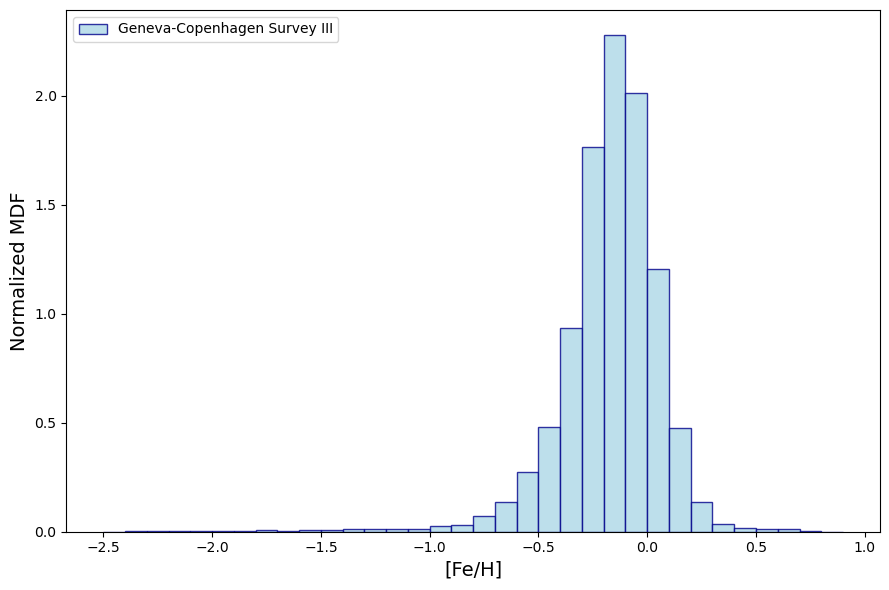

Total stars: 16394
Median [Fe/H]: -0.14
Metal-poor ([Fe/H] < -0.5): 5.996096132731487 %


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Histogram bins
bins = np.arange(-2.5, 1.0, 0.1)

plt.figure(figsize=(9, 6))

plt.hist(
    feh_gcs,
    bins=bins,
    density=True,
    color="lightblue",
    edgecolor="darkblue",
    alpha=0.8,
    label="Geneva-Copenhagen Survey III"
)

plt.xlabel("[Fe/H]", fontsize=14)
plt.ylabel("Normalized MDF", fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

print("Total stars:", len(feh_gcs))
print("Median [Fe/H]:", np.median(feh_gcs))
print("Metal-poor ([Fe/H] < -0.5):",
      np.mean(feh_gcs < -0.5) * 100, "%")

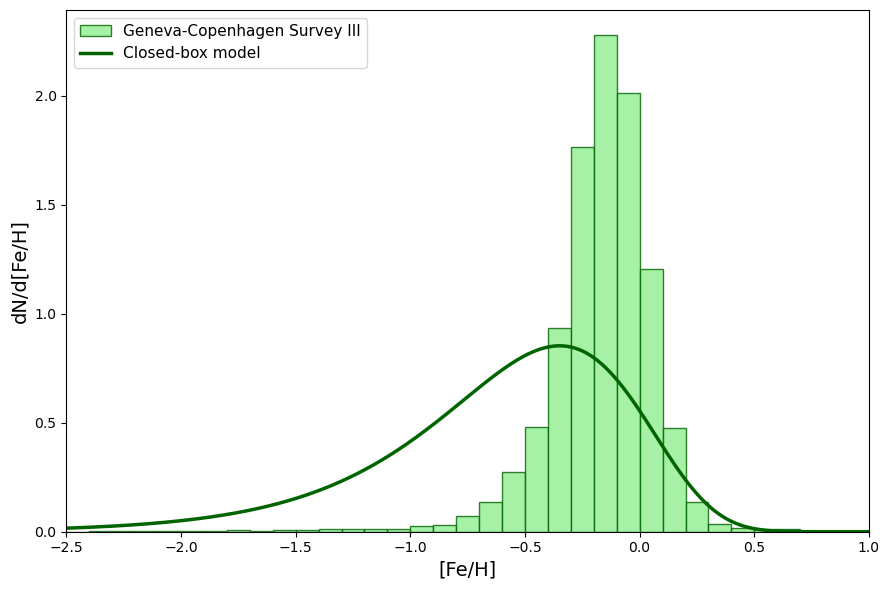

Total stars: 16394
Median [Fe/H]: -0.14
Metal-poor ([Fe/H] < -0.5): 5.996096132731487 %
Closed-box peak [Fe/H]: -0.3488488488488488


In [90]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================
# OBSERVED METALLICITY
# =====================================

feh_gcs = np.asarray(feh_gcs, dtype=float)
feh_gcs = feh_gcs[np.isfinite(feh_gcs)]


# =====================================
# CLOSED-BOX MODEL
# =====================================

z_sun = 0.0134
p = 0.006

mh_grid = np.linspace(-2.5, 1.0, 1000)

# Metallicity
Z = z_sun * 10**mh_grid

# Closed-box model in logarithmic metallicity
model = (np.log(10) / p) * Z * np.exp(-Z / p)

# Normalize model
dmh = mh_grid[1] - mh_grid[0]
model /= np.sum(model) * dmh


# =====================================
# HISTOGRAM
# =====================================

bins = np.arange(-2.5, 1.0, 0.1)

plt.figure(figsize=(9, 6))

plt.hist(
    feh_gcs,
    bins=bins,
    density=True,
    color="lightgreen",
    edgecolor="darkgreen",
    alpha=0.8,
    label="Geneva-Copenhagen Survey III"
)

plt.plot(
    mh_grid,
    model,
    color="darkgreen",
    linewidth=2.5,
    label="Closed-box model"
)
plt.xlabel("[Fe/H]", fontsize=14)
plt.ylabel("dN/d[Fe/H]", fontsize=14)
plt.xlim(-2.5, 1.0)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("Total stars:", len(feh_gcs))

print("Median [Fe/H]:", np.median(feh_gcs))

print(
    "Metal-poor ([Fe/H] < -0.5):",
    np.mean(feh_gcs < -0.5) * 100,
    "%"
)

print(
    "Closed-box peak [Fe/H]:",
    mh_grid[np.argmax(model)]
)

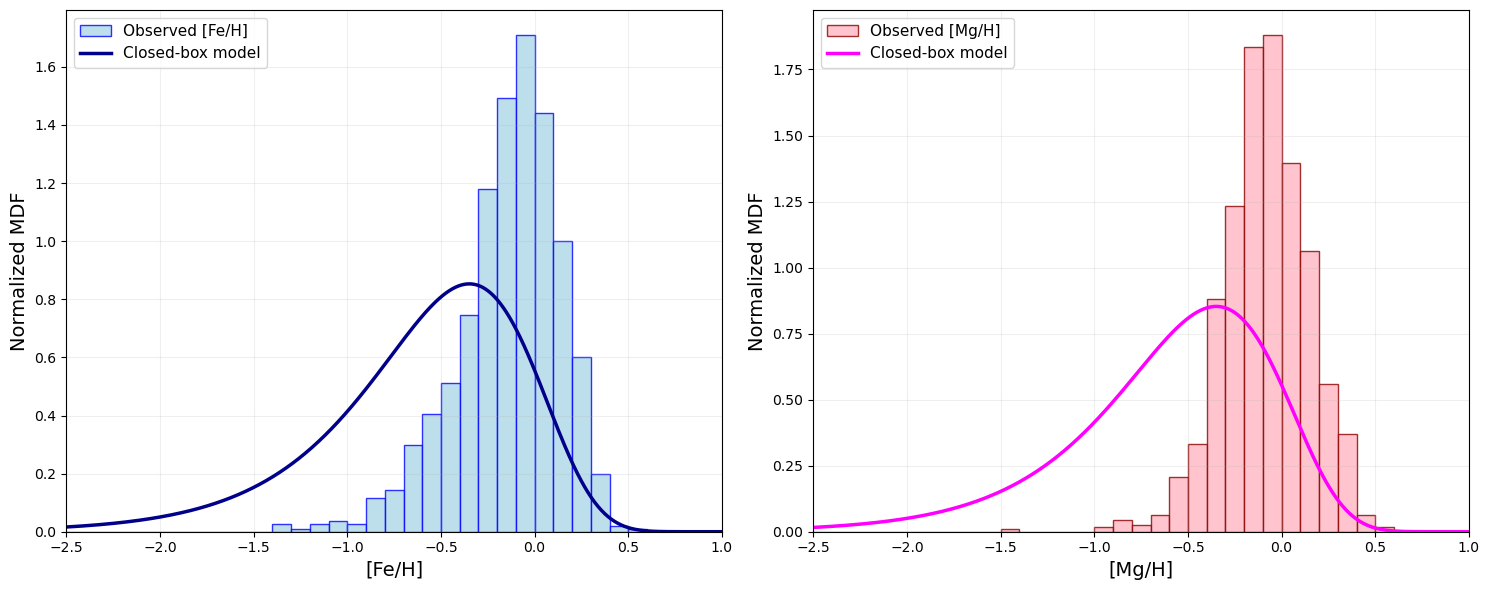

========== [Fe/H] ==========
Total stars: 1111
Median [Fe/H]: -0.1
Metal-poor ([Fe/H] < -0.5): 10.531053105310532 %
Closed-box peak [Fe/H]: -0.3488488488488488

========== [Mg/H] ==========
Total stars: 1111
Median [Mg/H]: -0.08
Metal-poor ([Mg/H] < -0.5): 3.5103510351035103 %
Closed-box peak [Mg/H]: -0.3488488488488488

========== NORMALIZATION ==========
Integral Closed-box: 1.0000000000000002
Integral Fe/H histogram: 1.0
Integral Mg/H histogram: 1.0


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================
# OBSERVED ABUNDANCES
# =====================================

feh_obs = pd.to_numeric(
    adi["[Fe/H]"], errors="coerce"
).to_numpy()

mgh_obs = pd.to_numeric(
    adi["[Mg/H]"], errors="coerce"
).to_numpy()

feh_obs = feh_obs[np.isfinite(feh_obs)]
mgh_obs = mgh_obs[np.isfinite(mgh_obs)]


# =====================================
# CLOSED-BOX MODEL
# =====================================

z_sun = 0.0134
p = 0.006

mh_grid = np.linspace(-2.5, 1.0, 1000)

# Metallicity
Z = z_sun * 10**mh_grid

# Closed-box MDF in logarithmic metallicity
model = (np.log(10) / p) * Z * np.exp(-Z / p)

# Normalize model
dmh = mh_grid[1] - mh_grid[0]
model /= np.sum(model) * dmh


# =====================================
# HISTOGRAM BINS
# =====================================

bins = np.arange(-2.5, 1.1, 0.1)


# =====================================
# TWO-PANEL COMPARISON
# =====================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))


# =====================================
# [Fe/H]
# =====================================

axes[0].hist(
    feh_obs,
    bins=bins,
    density=True,
    color="lightblue",
    edgecolor="blue",
    alpha=0.8,
    label="Observed [Fe/H]"
)

axes[0].plot(
    mh_grid,
    model,
    color="darkblue",
    linewidth=2.5,
    label="Closed-box model"
)

axes[0].set_xlabel("[Fe/H]", fontsize=14)
axes[0].set_ylabel("Normalized MDF", fontsize=14)
axes[0].set_xlim(-2.5, 1.0)
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.2)


# =====================================
# [Mg/H]
# =====================================

axes[1].hist(
    mgh_obs,
    bins=bins,
    density=True,
    color="lightpink",
    edgecolor="darkred",
    alpha=0.8,
    label="Observed [Mg/H]"
)

axes[1].plot(
    mh_grid,
    model,
    color="fuchsia",
    linewidth=2.5,
    label="Closed-box model"
)

axes[1].set_xlabel("[Mg/H]", fontsize=14)
axes[1].set_ylabel("Normalized MDF", fontsize=14)
axes[1].set_xlim(-2.5, 1.0)
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.2)


# =====================================
# FINAL LAYOUT
# =====================================

plt.tight_layout()
plt.savefig("ClosedBox_FeH_MgH.png", dpi=300)
plt.show()


# =====================================
# STATISTICS
# =====================================

print("========== [Fe/H] ==========")

print("Total stars:", len(feh_obs))
print("Median [Fe/H]:", np.median(feh_obs))

print(
    "Metal-poor ([Fe/H] < -0.5):",
    np.mean(feh_obs < -0.5) * 100, "%"
)

print(
    "Closed-box peak [Fe/H]:",
    mh_grid[np.argmax(model)]
)


print("\n========== [Mg/H] ==========")

print("Total stars:", len(mgh_obs))
print("Median [Mg/H]:", np.median(mgh_obs))

print(
    "Metal-poor ([Mg/H] < -0.5):",
    np.mean(mgh_obs < -0.5) * 100, "%"
)

print(
    "Closed-box peak [Mg/H]:",
    mh_grid[np.argmax(model)]
)


# =====================================
# NORMALIZATION CHECK
# =====================================

print("\n========== NORMALIZATION ==========")

print("Integral Closed-box:", np.sum(model) * dmh)
print("Integral Fe/H histogram:", np.sum(
    np.histogram(feh_obs, bins=bins, density=True)[0] *
    np.diff(bins)
))
print("Integral Mg/H histogram:", np.sum(
    np.histogram(mgh_obs, bins=bins, density=True)[0] *
    np.diff(bins)
))


#### Visualización: compare las 3 MDF en $[\mathrm{Fe/H}]$

Normalice los histogramas, ya que la cantidad de estrellas es distinta entre catálogos


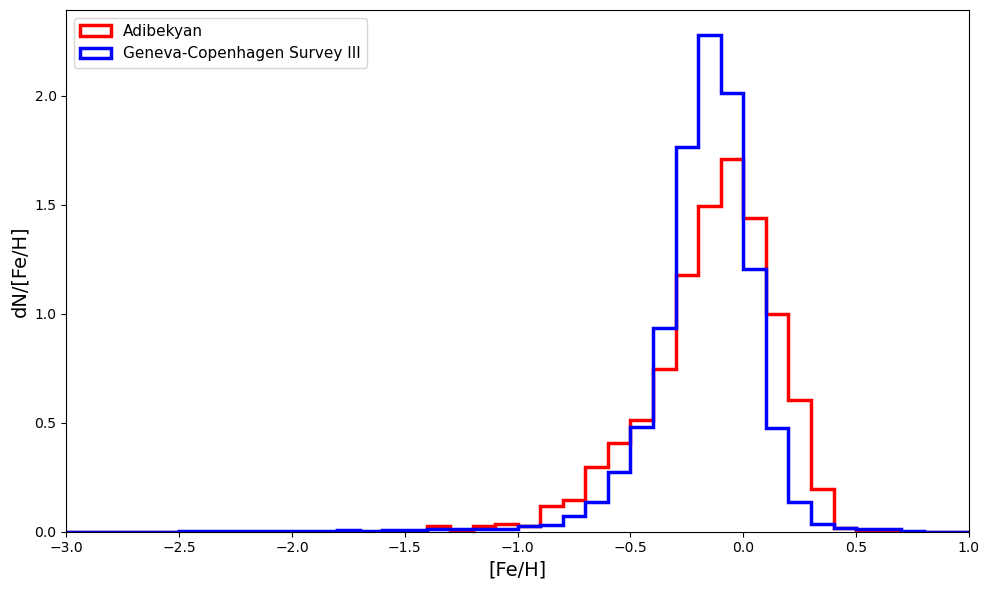


========== ADIBEKYAN ==========
Number of stars: 1111
Mean [Fe/H]: -0.1356975697569757
Median [Fe/H]: -0.1
Standard deviation: 0.27750987751484874
Metal-poor ([Fe/H] < -0.5): 10.531053105310532 %

========== GENEVA-COPENHAGEN III ==========
Number of stars: 16394
Mean [Fe/H]: -0.1665426375503233
Median [Fe/H]: -0.14
Standard deviation: 0.23717073921513407
Metal-poor ([Fe/H] < -0.5): 5.996096132731487 %
Adibekyan MDF integral: 1.0
GCS MDF integral: 1.0


In [92]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# =====================================
# ABUNDANCIAS OBSERVACIONALES
# =====================================

# Adibekyan
feh_obs = pd.to_numeric(
    adi["[Fe/H]"], errors="coerce"
).to_numpy(dtype=float)

feh_obs = feh_obs[np.isfinite(feh_obs)]

# Geneva-Copenhagen Survey III
feh_gcs = np.asarray(feh_gcs, dtype=float)
feh_gcs = feh_gcs[np.isfinite(feh_gcs)]


# =====================================
# MDF: MISMOS BINS
# =====================================

bins = np.arange(-3.0, 1.1, 0.1)

plt.figure(figsize=(10, 6))

# Adibekyan
plt.hist(
    feh_obs,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2.5,
    color="red",
    label="Adibekyan"
)

# Geneva-Copenhagen Survey III
plt.hist(
    feh_gcs,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2.5,
    color="blue",
    label="Geneva-Copenhagen Survey III"
)

# =====================================
# PLOT SETTINGS
# =====================================

plt.xlabel("[Fe/H]", fontsize=14)
plt.ylabel("dN/[Fe/H]", fontsize=14)

plt.xlim(-3, 1)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("MDF_Adibekyan_GCS.png", dpi=300)
plt.show()


# =====================================
# STATISTICS
# =====================================

print("\n========== ADIBEKYAN ==========")

print("Number of stars:", len(feh_obs))
print("Mean [Fe/H]:", np.mean(feh_obs))
print("Median [Fe/H]:", np.median(feh_obs))
print("Standard deviation:", np.std(feh_obs))

print(
    "Metal-poor ([Fe/H] < -0.5):",
    np.mean(feh_obs < -0.5) * 100, "%"
)


print("\n========== GENEVA-COPENHAGEN III ==========")

print("Number of stars:", len(feh_gcs))
print("Mean [Fe/H]:", np.mean(feh_gcs))
print("Median [Fe/H]:", np.median(feh_gcs))
print("Standard deviation:", np.std(feh_gcs))

print(
    "Metal-poor ([Fe/H] < -0.5):",
    np.mean(feh_gcs < -0.5) * 100, "%"
)


# =====================================
# NORMALIZATION CHECK
# =====================================

hist_adi, _ = np.histogram(
    feh_obs, bins=bins, density=True
)

hist_gcs, _ = np.histogram(
    feh_gcs, bins=bins, density=True
)
print("Adibekyan MDF integral:",
      np.sum(hist_adi * np.diff(bins)))

print("GCS MDF integral:",
      np.sum(hist_gcs * np.diff(bins)))


### Importante

Las tres MDF no corresponden exactamente a la misma selección de estrellas. Los catálogos difieren en tamaño de muestra, criterios de selección y técnicas utilizadas para estimar las abundancias.

Diferencias entre las curvas no deben interpretarse automáticamente como diferencias físicas en la evolución química de la Galaxia.



### $[\mathrm{Mg/H}]$ o $[\mathrm{Fe/H}]$  como proxy de $Z$

El modelo predice la cantidad de metales $Z$, mientras que las observaciones miden elementos individuales.

Supongamos que una estrella tiene aproximadamente la mitad de la metalicidad solar

$$
\frac{Z}{Z_\odot}=0.5
$$

Si Mg representa aproximadamente la misma fracción de los metales que en el Sol, entonces también esperamos aproximadamente la mitad de la abundancia solar de Mg

$$
\frac{(\mathrm{Mg/H})}{(\mathrm{Mg/H})_\odot}\approx0.5
$$

Por lo tanto

$$
[\mathrm{M/H}]
=
\log_{10}(0.5)
\approx
[\mathrm{Mg/H}]
$$

La idea no es que **Mg sea la metalicidad total**, sino que su abundancia puede utilizarse como indicador del nivel general de enriquecimiento químico.

Esta es una aproximación y debe justificarse.


#### Mg versus Fe

- **Mg**: Mg es un elemento $\alpha$ producido principalmente por estrellas masivas y liberado rápidamente al medio interestelar por supernovas de colapso del núcleo. 

- **Fe**: Fe también es un trazador muy utilizado de metalicidad. Sin embargo, una parte importante del Fe proviene de supernovas Ia, que enriquecen el medio con un retardo temporal.

Para comparar la MDF observada con la predicción del modelo deberán escoger uno de estos elementos como trazador de la metalicidad.
La elección debe ser justificada considerando:

- el origen del elemento
- su escala temporal de enriquecimiento
- las hipótesis del closed-box model
- las limitaciones de utilizar un elemento individual como proxy de $Z$


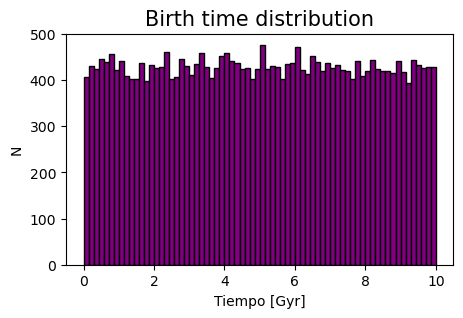

In [68]:
#aqui si incluye 0.08
np.random.seed(42)
N = 30000
def mckroupa(n_estrellas, m_min=0.01, m_max=100.0, edad_galaxia=10.0):
    tiempos_nacimiento = np.random.uniform(0, edad_galaxia, n_estrellas) #tiempo uniforme
    limites = np.array([m_min, 0.08, 0.50, 1.00, m_max]) #masas limite para cada tramo
    alpha = np.array([0.3, 1.3, 2.3, 2.3]) #exponentes de acuerdo a Kroupa 2001
    #pesos y normalización 
    constantes = np.zeros(4)
    constantes[0] = 1.0
    for i in range(1, 4):
        constantes[i] = (constantes[i-1]* limites[i]**(alpha[i] - alpha[i-1]))
    pesos = np.zeros(4)
    for i in range(4):
        lo, hi = limites[i], limites[i+1]
        a = alpha[i]
        if np.isclose(a, 1.0):
            integral = np.log(hi / lo)
        else:
            integral = (
                hi**(1-a) - lo**(1-a)
            ) / (1-a)

        pesos[i] = constantes[i] * integral

    probabilidades = pesos / pesos.sum() #prob. para cada tramo
    tramos = np.random.choice(4, size=n_estrellas, p=probabilidades)
    masas = np.empty(n_estrellas)
    # Muestreo invers de la distribución de potencia
    for i in range(4):
        mask = tramos == i
        n = mask.sum()

        if n == 0:
            continue

        lo, hi = limites[i], limites[i+1]
        a = alpha[i]
        u = np.random.uniform(0, 1, n)

        if np.isclose(a, 1.0):
            masas[mask] = lo * (hi / lo)**u
        else:
            masas[mask] = (lo**(1-a)+ u * (hi**(1-a) - lo**(1-a)))**(1/(1-a))

    return masas, tiempos_nacimiento

mmin=0.01
mmax=100.0
galaxy_age=10 #Gyr
masas_simuladas, tiempos_simulados = mckroupa(N,mmin, mmax, galaxy_age)
plt.figure(figsize=(5,3))
plt.hist(tiempos_simulados, bins=70,color="purple", edgecolor="black")
plt.xlabel("Tiempo [Gyr]",fontsize=10)
plt.ylabel("N",fontsize=10)
plt.title("Birth time distribution",fontsize=15)
plt.show()

In [74]:
Z_sun=0.014     #metalicidad incial
T_MW=10.0       #Gyr
mu_f=0.10       #Fracción final de gas

masas, t_birth = mckroupa(N, m_min=0.01, m_max=100, edad_galaxia=T_MW)

y = Z_sun/np.log(1.0/mu_f) # Yield efectivo para que Z_gas(T_MW) = Z_sun
def mu_gas(t):
    return 1.0-(1.0-mu_f)*t/T_MW #evolución fracción de gas

def Z_gas(t):
    return y*np.log(1.0 / mu_gas(t)) #evolución de la metalicidad del gas
    
Z_birth = Z_gas(t_birth) #Metalicidad en el nacimiento de cada estrella
#Metalicidad logarítmica relativa al Sol
MH_birth = np.log10(Z_birth/Z_sun)

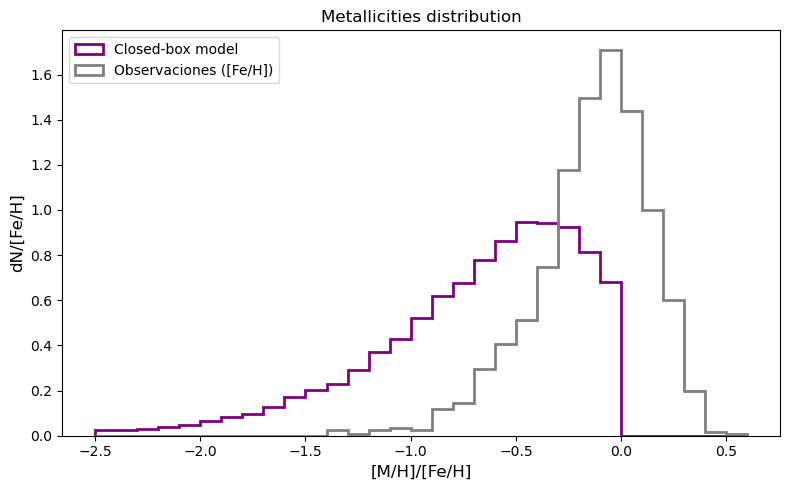

In [77]:
# Z_birth debe contener las metalicidades
# de nacimiento predichas por el modelo.
Z_birth = Z_gas(t_birth)  # Reemplazar por los datos calculados anteriormente
mh_model = np.log10(Z_birth/Z_sun)
proxy_obs = feh_obs #el trazador escogido
bins = np.arange(-2.5, 0.7, 0.1)
plt.figure(figsize=(8, 5))
plt.hist(
    mh_model,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    color="purple",
    label="Closed-box model"
)
plt.hist(
    proxy_obs,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    color="grey",
    label="Observaciones ([Fe/H])"
)
plt.xlabel("[M/H]/[Fe/H]", fontsize=12)
plt.ylabel("dN/[Fe/H]", fontsize=12)
plt.title("Metallicities distribution")
plt.legend()
plt.tight_layout()
plt.show()


## Referencias de catálogos

- Adibekyan, V. Zh. et al. 2012, *A&A*, **545**, A32
- Haywood, M. 2001, *MNRAS*, **325**, 1365
- Holmberg, J., Nordström, B. & Andersen, J. 2009, *A&A*, **501**, 941
- Bovy, J., *Dynamics and Astrophysics of Galaxies*, capítulo de evolución química galáctica


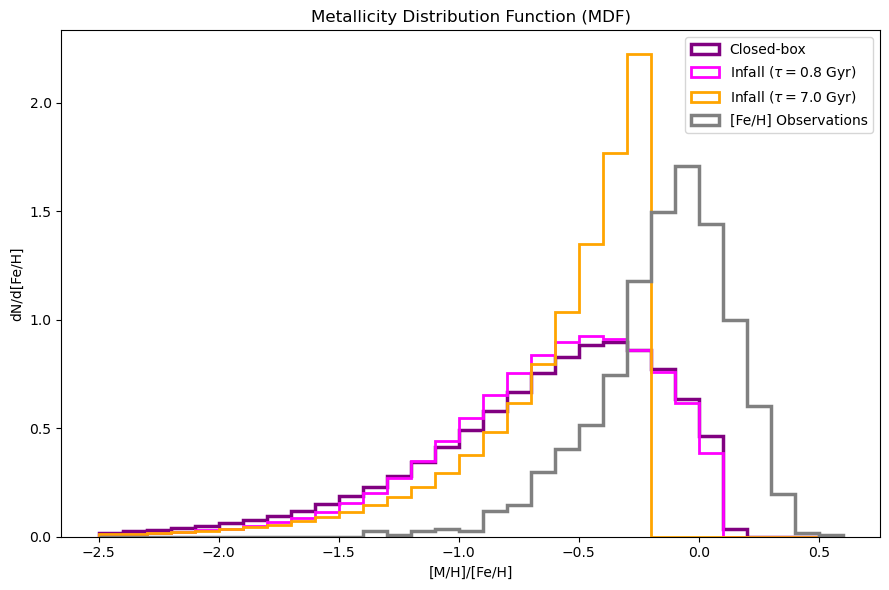

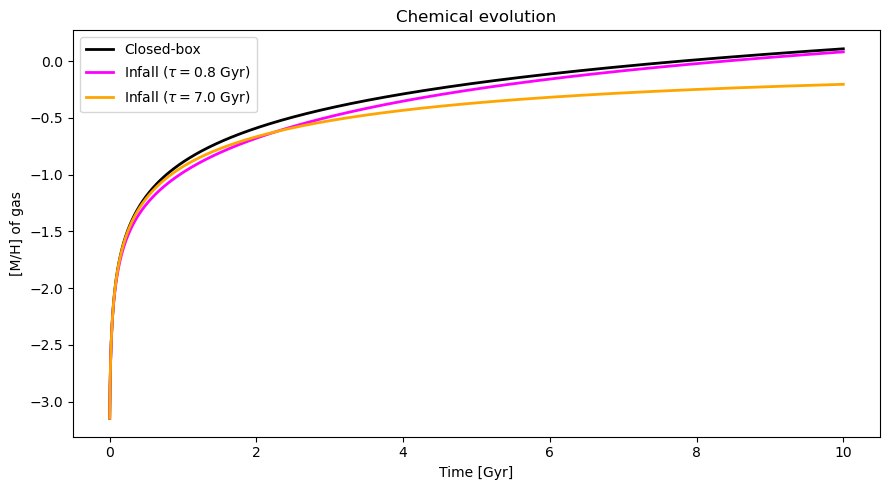

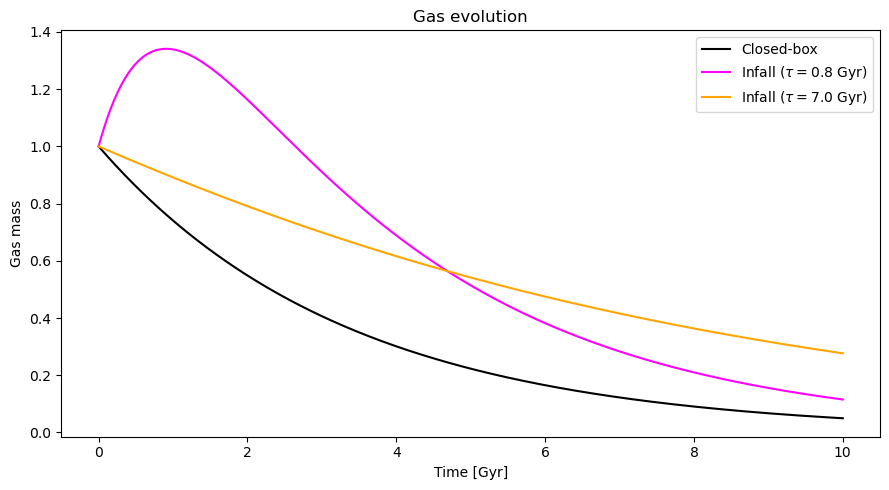

Closed-box: 0.2178
Infall tau=0.8 Gyr: 0.1888
Infall tau=7.0 Gyr: 0.1387
Closed-box: media=-0.658, dispersion=0.523
Infall tau=0.8 Gyr: media=-0.632, dispersion=0.464
Infall tau=7.0 Gyr: media=-0.603, dispersion=0.406


In [89]:
T = 10.0
dt = 0.001
time = np.arange(0, T + dt, dt)
# Masa inicial de gas
Mg0 = 1.0
# Fraccion de masa devuelta por las estrellas
R = 0.4

# Eficiencia de formacion estelar (Gyr^-1)
nu = 0.5

# Yield efectivo de metales
y = 0.006
Z0 = 1e-5# Metalicidad inicial del gas
Zin = 0.0#Metalicidad del gas acretado
f_infall = 1.0 #Fraccion de masa adicional que entra por infall

tau_values = [0.8, 7.0]#USANDO CHIAPPINI

# Metalicidad solar
Z_sun = 0.014
#chemical evolution
def chemical_evolution(tau=None):
    Mg = np.zeros(len(time))
    Z = np.zeros(len(time))
    sfr = np.zeros(len(time))
    accretion = np.zeros(len(time))

    # Condiciones iniciales
    Mg[0] = Mg0
    Z[0] = Z0

    # Closed-box: sin acrecion
    if tau is None:
        A0 = 0.0

    else:
        # Normalizacion para mantener constante
        # la masa total acretada entre los modelos
        A0 = (
            f_infall * Mg0 /
            (tau * (1 - np.exp(-T / tau)))
        )
    for i in range(len(time) - 1):

        t = time[i]
        # Tasa de formacion estelar
        sfr[i] = nu * Mg[i]
        # Tasa de acrecion
        accretion[i] = A0 * np.exp(-t / tau) if tau is not None else 0.0
        # Conservacion de masa de gas
        dMg = (
            -(1 - R) * sfr[i]
            + accretion[i]
        )
        # Conservacion de metales
        dZ = (
            y * (1 - R) * sfr[i]
            + (Zin - Z[i]) * accretion[i]
        ) / Mg[i]
        #loop 
        Mg[i+1] = Mg[i] + dMg * dt
        Z[i+1] = Z[i] + dZ * dt

        # Evitar valores negativos
        Mg[i+1] = max(Mg[i+1], 1e-12)
        Z[i+1] = max(Z[i+1], 1e-12)

    sfr[-1] = nu * Mg[-1]

    return Mg, Z, sfr, accretion

Mg_cb, Z_cb, sfr_cb, A_cb = chemical_evolution() #caja cerrada
#infall
results = {}
for tau in tau_values:
    results[tau] = chemical_evolution(tau)
def stellar_mdf(Z, sfr):#metallicity estrellas jovenes
    # Metalicidad de nacimiento
    mh = np.log10(Z / Z_sun)
    # Peso proporcional al numero de estrellas formadas
    weights = sfr * dt
    return mh, weights
mh_cb, weights_cb = stellar_mdf(Z_cb, sfr_cb)
# Histogramas
bins = np.arange(-2.5, 0.7, 0.1)
plt.figure(figsize=(9, 6))
plt.hist(
    mh_cb,
    bins=bins,
    weights=weights_cb,
    density=True,
    histtype="step",
    linewidth=2.5,
    color="purple",
    label="Closed-box"
)

colors = ["fuchsia", "orange"]
for j, tau in enumerate(tau_values):
    Mg, Z, sfr, A = results[tau]
    mh, weights = stellar_mdf(Z, sfr)
    plt.hist(
        mh,
        bins=bins,
        weights=weights,
        density=True,
        histtype="step",
        linewidth=2,
        color=colors[j],
        label=fr"Infall ($\tau={tau}$ Gyr)"
    )

# Observaciones
proxy_obs = feh_obs
plt.hist(
    proxy_obs,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2.5,
    color="grey",
    label="[Fe/H] Observations"
)

plt.xlabel("[M/H]/[Fe/H]")
plt.ylabel("dN/d[Fe/H]")
plt.title("Metallicity Distribution Function (MDF)")

plt.legend()
plt.tight_layout()
plt.show()

#gas metallicity
plt.figure(figsize=(9, 5))

plt.plot(
    time,
    np.log10(Z_cb / Z_sun),
    color="black",
    linewidth=2,
    label="Closed-box"
)

for j, tau in enumerate(tau_values):

    Mg, Z, sfr, A = results[tau]

    plt.plot(
        time,
        np.log10(Z / Z_sun),
        color=colors[j],
        linewidth=2,
        label=fr"Infall ($\tau={tau}$ Gyr)"
    )

plt.xlabel("Time [Gyr]")
plt.ylabel("[M/H] of gas")
plt.title("Chemical evolution")
plt.legend()
plt.tight_layout()
plt.show()
plt.figure(figsize=(9, 5))

plt.plot(time, Mg_cb, color="black", label="Closed-box")

for j, tau in enumerate(tau_values):

    Mg, Z, sfr, A = results[tau]

    plt.plot(
        time,
        Mg,
        color=colors[j],
        label=fr"Infall ($\tau={tau}$ Gyr)"
    )

plt.xlabel("Time [Gyr]")
plt.ylabel("Gas mass")
plt.title("Gas evolution")

plt.legend()
plt.tight_layout()
plt.show()

threshold = -1.0
def metal_poor_fraction(mh, weights):
    return np.sum(weights[mh < threshold]) / np.sum(weights)
f_cb = metal_poor_fraction(mh_cb, weights_cb) #fraccion metal poors
print(f"Closed-box: {f_cb:.4f}")
for tau in tau_values:
    Mg, Z, sfr, A = results[tau]
    mh, weights = stellar_mdf(Z, sfr)
    f_mp = metal_poor_fraction(mh, weights)
    print(f"Infall tau={tau} Gyr: {f_mp:.4f}")
def mdf_statistics(mh, weights): #ancho mdf
    mean = np.average(mh, weights=weights)
    variance = np.average(
        (mh - mean)**2,
        weights=weights
    )
    return mean, np.sqrt(variance)
mean_cb, std_cb = mdf_statistics(mh_cb, weights_cb)

print(
    f"Closed-box: media={mean_cb:.3f}, "
    f"dispersion={std_cb:.3f}"
)
for tau in tau_values:

    Mg, Z, sfr, A = results[tau]

    mh, weights = stellar_mdf(Z, sfr)

    mean, std = mdf_statistics(mh, weights)

    print(
        f"Infall tau={tau} Gyr: "
        f"media={mean:.3f}, dispersion={std:.3f}"
    )